In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#loading dataset
data = pd.read_csv(r"/content/BankNote_Authentication.csv")
print("Shape:", data.shape)
print(data.head())

Shape: (1372, 5)
   variance  skewness  curtosis  entropy  class
0   3.62160    8.6661   -2.8073 -0.44699      0
1   4.54590    8.1674   -2.4586 -1.46210      0
2   3.86600   -2.6383    1.9242  0.10645      0
3   3.45660    9.5228   -4.0112 -3.59440      0
4   0.32924   -4.4552    4.5718 -0.98880      0


In [ ]:
#preprocessing
print("Missing values:", data.isnull().sum().sum())

data = data.drop_duplicates()

print("Class counts:", data.iloc[:, -1].value_counts())

X = data.iloc[:, :-1].values
y = data.iloc[:, -1].values

np.random.seed(42)
indexes = np.random.permutation(len(X))
X = X[indexes]
y = y[indexes]

split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]


mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
X_train = (X_train - mean) / std
X_test = (X_test - mean) / std


Missing values: 0
Class counts: class
0    738
1    610
Name: count, dtype: int64


In [ ]:
class Perceptron:
    def __init__(self, learning_rate=0.01, epochs=100):
        self.lr = learning_rate
        self.epochs = epochs

    def step(self, z):
        #Step activation function
        return np.where(z >= 0, 1, 0)

    def fit(self, X, y):
        self.w = np.zeros(X.shape[1])   #weights
        self.b = 0                      #bias
        self.errors = []   #mistakes in each epoch

        for epoch in range(self.epochs):
            mistakes = 0
            for xi, target in zip(X, y):
                z = np.dot(xi, self.w) + self.b
                prediction = self.step(z)
                update = self.lr * (target - prediction)
                self.w = self.w + update * xi
                self.b = self.b + update
                if update != 0:
                    mistakes += 1
            self.errors.append(mistakes)

    def predict(self, X):
        z = np.dot(X, self.w) + self.b
        return self.step(z)

In [ ]:
model = Perceptron(learning_rate=0.01, epochs=100)
model.fit(X_train, y_train)

print("Final weights:", model.w)
print("Final bias:", model.b)
y_pred = model.predict(X_test)

Final weights: [-0.19643788 -0.26232796 -0.21223577 -0.02551139]
Final bias: -0.09


In [ ]:
TP = np.sum((y_test == 1) & (y_pred == 1))
TN = np.sum((y_test == 0) & (y_pred == 0))
FP = np.sum((y_test == 0) & (y_pred == 1))
FN = np.sum((y_test == 1) & (y_pred == 0))

accuracy = (TP + TN) / (TP + TN + FP + FN)
precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0
f1 = 2 * precision * recall / (precision + recall)if (precision + recall) > 0 else 0

print("FINAL RESULTS")
print("Confusion Matrix:")
print("True Negative (TN):", TN)
print("False Positive (FP):", FP)
print("False Negative (FN):", FN)
print("True Positive (TP):", TP)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))

FINAL RESULTS
Confusion Matrix:
True Negative (TN): 136
False Positive (FP): 2
False Negative (FN): 0
True Positive (TP): 132
Accuracy : 0.9926
Precision: 0.9851
Recall: 1.0
F1-score: 0.9925


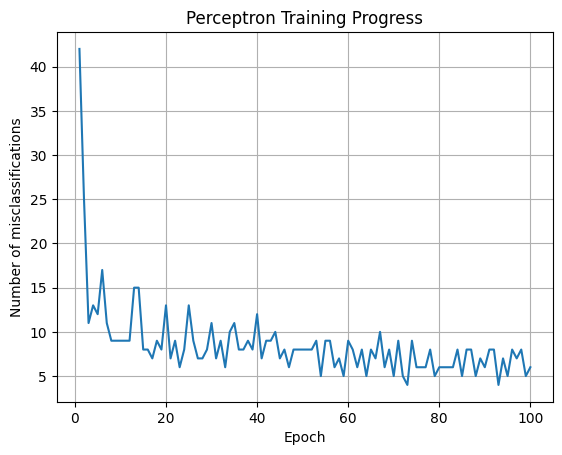

In [ ]:
plt.plot(range(1, len(model.errors) + 1), model.errors)
plt.xlabel("Epoch")
plt.ylabel("Number of misclassifications")
plt.title("Perceptron Training Progress")
plt.grid(True)
plt.show()